# Tiny Transformer for Legal Act Classification

Cluster 6. Lightweight Transformer Models for Kazakh Text

Датасет KazakhLawCorpus-clean (215.9K нормативных правовых актов на казахском языке). Задача классифицировать акт по форме (`act_form`) по его названию.

Сравниваются три модели на временном разбиении
1. TF-IDF (словные и символьные n-граммы) + LogisticRegression
2. Компактный трансформер с нуля (собственный BPE-токенизатор, до 10 млн параметров)
3. Дообученная intfloat/multilingual-e5-small

Мамбеталы Нурайдар, ADA-2602M

## 0. Окружение

In [ ]:
!pip -q install datasets tokenizers transformers scikit-learn

In [ ]:
import os, re, time, json, sqlite3, random, copy, math, shutil, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders, processors
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
TARGET = "act_form"
MIN_CLASS_COUNT = 300
MIN_VAL_COUNT = 10
NEAR_DUP_THRESHOLD = 0.9
E5_NAME = "intfloat/multilingual-e5-small"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
E5_TRAIN_SIZE = 60000 if DEVICE == "cuda" else 12000
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = f"/content/drive/MyDrive/pdad_tiny_transformer/{TARGET}_v2"
except ImportError:
    OUT = f"artifacts/{TARGET}_v2"
os.makedirs(OUT, exist_ok=True)
DB_BACKUP = f"{OUT}/experiments.db"
DB_PATH = f"experiments_{TARGET}.db"
if os.path.exists(DB_BACKUP) and not os.path.exists(DB_PATH):
    shutil.copy(DB_BACKUP, DB_PATH)

def save_json(obj, name):
    with open(f"{OUT}/{name}", "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False)

def load_json(name):
    with open(f"{OUT}/{name}", encoding="utf-8") as f:
        return json.load(f)

def has(name):
    return os.path.exists(f"{OUT}/{name}")

print("папка результатов", OUT)
print("уже сохранено", sorted(os.listdir(OUT)))

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed()
print("device", DEVICE)
print("torch", torch.__version__)

Mounted at /content/drive
папка результатов /content/drive/MyDrive/pdad_tiny_transformer/act_form_v2
уже сохранено []
device cuda
torch 2.14.1+cu130


## 1. Загрузка данных

In [ ]:
raw = load_dataset("Arailym-tleubayeva/KazakhLawCorpus-clean", split="train").to_pandas().reset_index(drop=True)
print(raw.shape)
raw.head(3)

README.md:   0%|          | 0.00/11.2k [00:00<?, ?B/s]

data/kazakhlawcorpus_kk_only.csv: reconstructing file:   0%|          |  0.00B /  337MB            

data/kazakhlawcorpus_kk_only.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/215889 [00:00<?, ? examples/s]

(215889, 25)


,source_id,law_id,date_adopted,date_modified,date_published,state_registry_number,law_registry_number,gov_registration_number,ministry_registration_date,is_archive,...,official_publication_info,act_form,legal_relation_area,legal_force,adopting_body,regulatory_body,developer_body,region,place_of_adoption,database_section
0,223103,A04C0000417,2004-07-15,None,None,NaN,417,None,None,f,...,ЖОҚ,Бұйрық,"Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, мемлекеттік есепке алу",Қалғандары,Қазақстан Республикасының Ішкі істер министрлігі,ЖОҚ,None,Қазақстан Республикасы,Астана қаласы,Конституциялық құрылыс және мемлекеттік басқару негіздері
1,215496,A05I0001722,2005-04-18,None,None,NaN,151-I,undefined,None,f,...,ЖОҚ,Бұйрық,"Су көлігі, Көліктегі қауіпсіздік, Нормативтік құқықтық актілер: дайындау, қабылдау, өзгерту, жариялау, түсіндіру, ме...",Министрлік пен ведомствоның актісі,Қазақстан Республикасының Көлік және коммуникациялар министрлігі (ҚР Президентінің 06.08.2014 ж. N 875 Жарлығымен та...,ЖОҚ,None,Қазақстан Республикасы,Астана қаласы,Көлік
2,214892,A06C0001819,2006-12-30,None,None,NaN,606,undefined,None,f,...,ЖОҚ,Бұйрық,Ішкі істер органдары. Жол полициясы,Министрлік пен ведомствоның актісі,Қазақстан Республикасының Ішкі істер министрлігі,ЖОҚ,None,Қазақстан Республикасы,Астана қаласы,Ұлттық қауіпсіздік. Қоғамдық тәртіпті қорғау


In [ ]:
print(raw.dtypes)

source_id                       int64
law_id                         object
date_adopted                   object
date_modified                  object
date_published                 object
state_registry_number         float64
law_registry_number            object
gov_registration_number        object
ministry_registration_date     object
is_archive                     object
is_repealed                    object
adilet_url                     object
ekb_url                        object
title                          object
description                    object
official_publication_info      object
act_form                       object
legal_relation_area            object
legal_force                    object
adopting_body                  object
regulatory_body                object
developer_body                 object
region                         object
place_of_adoption              object
database_section               object
dtype: object


## 2. EDA

### 2.1 Пропуски

In [ ]:
EMPTY = {"", "жоқ", "none", "nan", "null"}

def is_empty(x):
    return pd.isna(x) or str(x).strip().lower() in EMPTY

missing = pd.DataFrame({
    "null_share": raw.isna().mean(),
    "empty_or_null_share": raw.apply(lambda c: c.map(is_empty).mean())
}).sort_values("empty_or_null_share", ascending=False).round(4)
missing

,null_share,empty_or_null_share
date_published,0.8836,0.8836
ministry_registration_date,0.8662,0.8662
developer_body,0.6872,0.7026
date_modified,0.4955,0.4955
regulatory_body,0.0001,0.4321
official_publication_info,0.0044,0.1927
ekb_url,0.1563,0.1563
state_registry_number,0.1430,0.1430
gov_registration_number,0.1164,0.1164
adilet_url,0.0037,0.0037


### 2.2 Целевая переменная

In [ ]:
for col in ["act_form", "legal_relation_area"]:
    s = raw[col].dropna().astype(str)
    print(col, "уникальных значений", s.nunique(), "доля значений с несколькими формами", round(s.str.contains(",").mean(), 4))
print(raw["act_form"].value_counts().head(25).to_string())

act_form уникальных значений 862 доля значений с несколькими формами 0.4258
legal_relation_area уникальных значений 25284 доля значений с несколькими формами 0.7731
act_form
Шешім                         58192
Қаулы                         47794
Шешім, Өзгерту                16970
Өзгерту, Шешім                 9418
Бұйрық                         7314
Бұйрық, Өзгерту                6341
Өкім                           3948
Қаулы, Жоба                    3900
Қаулы, Өзгерту                 3459
Қағида, Бұйрық                 3091
Жарлық                         3021
Қаулы, Қағида                  2700
Бұйрық, Өзгерту, Толықтыру     2605
Өзгерту, Қаулы                 2585
Қаулы, Регламент               2432
Өзгерту, Бұйрық                2156
Бұйрық, Қағида                 1876
Заң                            1664
Қағида, Шешім                  1625
Қаулы, Тізбе                   1571
Ереже, Қаулы                   1547
Қаулы, Шешім                   1389
Шешім, Өзгерту, Толықтыру      137

In [ ]:
MAIN_FORMS = ["Конституциялық Заң", "Заң күші бар Жарлық", "Заң", "Жарлық", "Нормативтік қаулы", "Қаулы",
              "Бұйрық", "Шешім", "Өкім", "Жолдау", "Шарт", "Келісім", "Хаттама", "Конвенция"]

def clean_label(x):
    if is_empty(x):
        return np.nan
    parts = [t.strip() for t in re.split(r"[;,|]", str(x)) if t.strip()]
    for f in MAIN_FORMS:
        if f in parts:
            return f
    return parts[0] if parts else np.nan

def norm_text(x):
    x = str(x).lower().replace("ё", "е")
    x = re.sub(r"[«»\"“”„]", " ", x)
    x = re.sub(r"\s+", " ", x)
    return x.strip()

df = raw.copy()
df["label"] = df[TARGET].map(clean_label)
df["label_first"] = df[TARGET].map(lambda x: np.nan if is_empty(x) else re.split(r"[;,|]", str(x))[0].strip())
df["title"] = df["title"].where(~df["title"].map(is_empty))
df["title_norm"] = df["title"].map(lambda x: norm_text(x) if isinstance(x, str) else np.nan)
df["date"] = pd.to_datetime(df["date_adopted"], errors="coerce")
df["year"] = df["date"].dt.year

print("строк всего", len(df))
print("нет title", df["title"].isna().sum())
print("нет метки", df["label"].isna().sum())
print("нет даты", df["date"].isna().sum())
print("годы вне 1990 2026", ((df["year"] < 1990) | (df["year"] > 2026)).sum())

строк всего 215889
нет title 0
нет метки 63
нет даты 0
годы вне 1990 2026 53


In [ ]:
print("метка по первому значению")
print(df["label_first"].value_counts().head(12).to_string())
print()
print("метка по основной форме акта")
print(df["label"].value_counts().head(12).to_string())

метка по первому значению
label_first
Шешім        79176
Қаулы        70313
Бұйрық       22480
Өзгерту      15399
Қағида        5163
Өкім          4366
Толықтыру     4151
Жарлық        3566
Заң           3131
Ереже         2419
Әдістеме      1355
Нұсқаулық      588

метка по основной форме акта
label
Шешім                93063
Қаулы                77979
Бұйрық               30250
Өкім                  4625
Жарлық                4087
Заң                   3443
Нормативтік қаулы      593
Қағида                 325
Нұсқаулық              240
Ереже                  192
Жоба                   163
Келісім                112


В поле act_form несколько значений перечислены по алфавиту (например «Өзгерту, Шешім» или «Қағида, Қаулы»), поэтому первое значение часто оказывается не формой акта, а типом изменения или приложения. Метка берётся как основная форма акта из списка MAIN_FORMS, а если её нет, то первое значение.

In [ ]:
vc = df["label"].value_counts()
print("классов", len(vc))
print(vc.head(30).to_string())

классов 53
label
Шешім                  93063
Қаулы                  77979
Бұйрық                 30250
Өкім                    4625
Жарлық                  4087
Заң                     3443
Нормативтік қаулы        593
Қағида                   325
Нұсқаулық                240
Ереже                    192
Жоба                     163
Келісім                  112
Ұсынымдар                103
Конституциялық Заң        88
Заң күші бар Жарлық       69
Өзгерту                   65
Түсінік                   59
Жолдау                    58
Жіктеу                    46
Бағдарлама                39
Кодекс                    36
Тәртіп                    35
Декларация                30
Хат                       17
Қағидат                   10
Тізбе                     10
Толықтыру                  9
Хаттама                    9
Стандарт                   7
Жоспар                     6


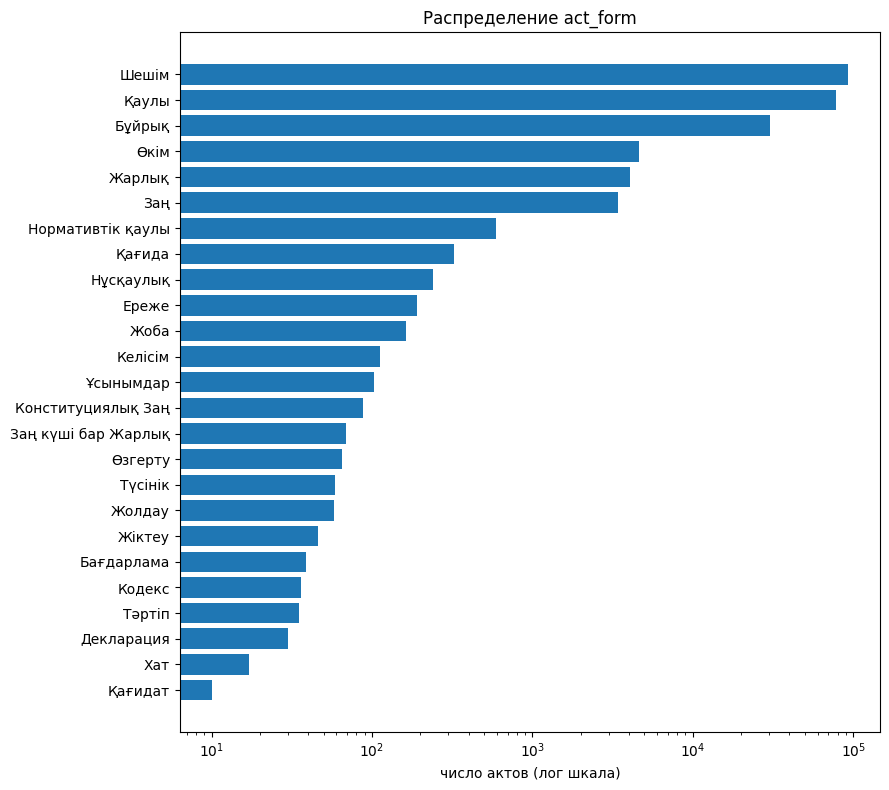

In [ ]:
top = vc.head(25)[::-1]
plt.figure(figsize=(9, 8))
plt.barh(top.index, top.values)
plt.xscale("log")
plt.xlabel("число актов (лог шкала)")
plt.title(f"Распределение {TARGET}")
plt.tight_layout()
plt.show()

### 2.3 Дубликаты

In [ ]:
print("полные дубликаты строк", raw.astype(str).duplicated().sum())
print("дубликаты law_id", df["law_id"].duplicated().sum())
print("дубликаты title_norm", df["title_norm"].dropna().duplicated().sum())
g = df.dropna(subset=["title_norm", "label"]).groupby("title_norm")["label"].nunique()
print("названий с разными метками", (g > 1).sum())
print("доля уникальных названий", round(df["title_norm"].nunique() / df["title_norm"].notna().sum(), 4))

полные дубликаты строк 0
дубликаты law_id 0
дубликаты title_norm 55670
названий с разными метками 798
доля уникальных названий 0.7421


In [ ]:
dup_titles = df["title_norm"].value_counts().head(10)
dup_titles

,count
title_norm,
қауымдық сервитут белгілеу туралы,667
шектеу іс-шараларын белгілеу туралы,588
қазақстан республикасы үкіметінің резервінен қаражат бөлу туралы,410
қазақстан республикасы үкіметінің кейбір шешімдерінің күші жойылды деп тану туралы,387
"әлеуметтік көмек көрсетудің, оның мөлшерлерін белгілеудің және мұқтаж азаматтардың жекелеген санаттарының тізбесін айқындаудың қағидаларын бекіту туралы",190
қазақстан республикасы үкіметінің кейбір шешімдеріне өзгерістер мен толықтырулар енгізу туралы,190
көшелерге атау беру туралы,185
жер учаскесіне қауымдық сервитут белгілеу туралы,179
қазақстан республикасы үкіметінің кейбір шешімдеріне өзгерістер енгізу туралы,172


### 2.4 Длины названий в токенах

In [ ]:
d = df.dropna(subset=["title_norm"])
d_words = d["title_norm"].str.split().str.len()
d_chars = d["title_norm"].str.len()
e5_tok = AutoTokenizer.from_pretrained(E5_NAME)
sample_titles = d["title_norm"].sample(min(20000, len(d)), random_state=SEED).tolist()
d_e5 = np.array([len(x) for x in e5_tok(sample_titles, add_special_tokens=True)["input_ids"]])

stats = pd.DataFrame({
    "слова": d_words.describe(percentiles=[.5, .9, .95, .99]),
    "символы": d_chars.describe(percentiles=[.5, .9, .95, .99]),
    "e5 subword": pd.Series(d_e5).describe(percentiles=[.5, .9, .95, .99]),
}).round(1)
stats

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

,слова,символы,e5 subword
count,215889.0,215889.0,20000.0
mean,20.0,166.5,35.7
std,11.2,94.3,19.7
min,1.0,4.0,3.0
50%,19.0,156.0,33.0
90%,33.0,276.0,59.0
95%,40.0,335.0,71.0
99%,58.0,491.0,106.0
max,525.0,4066.0,247.0


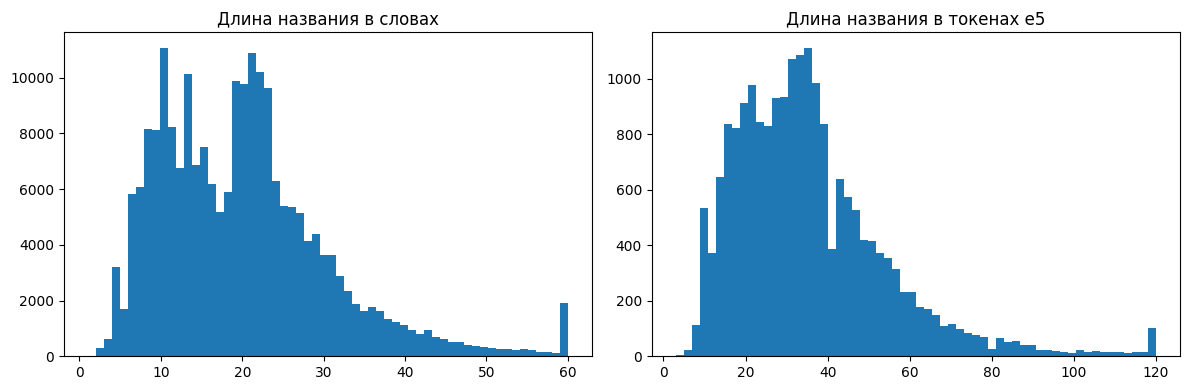

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(d_words.clip(upper=60), bins=60)
ax[0].set_title("Длина названия в словах")
ax[1].hist(np.clip(d_e5, 0, 120), bins=60)
ax[1].set_title("Длина названия в токенах e5")
plt.tight_layout()
plt.show()

### 2.5 Распределение по времени

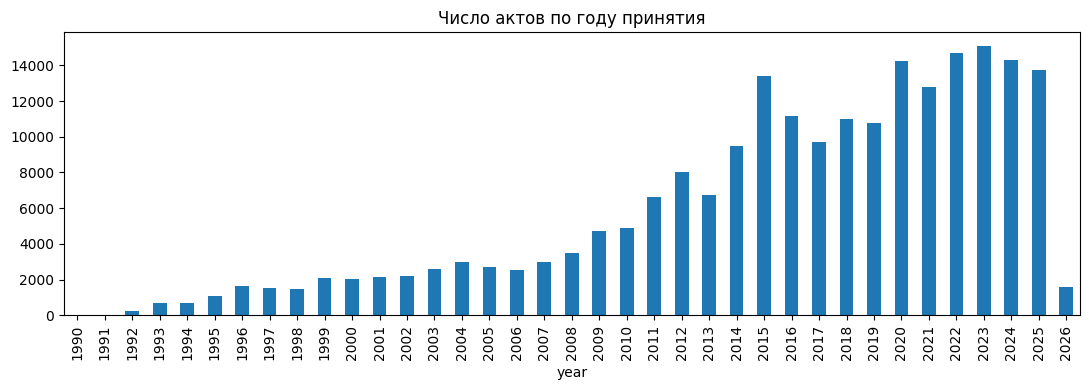

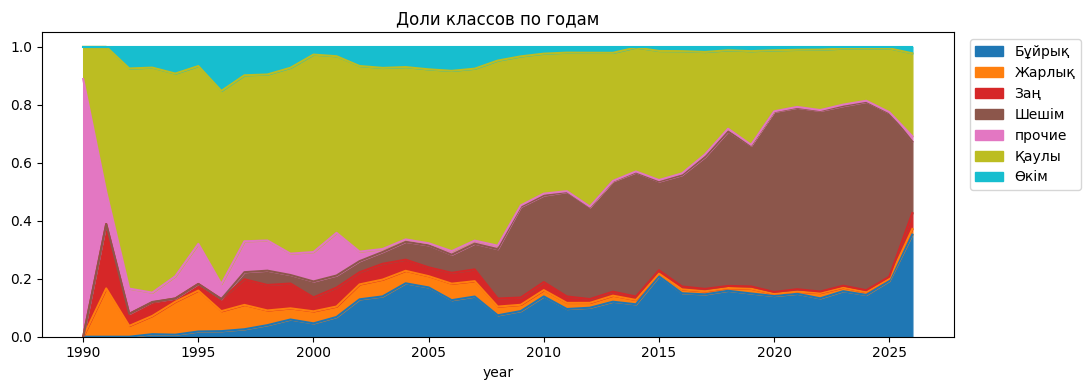

In [ ]:
y = df[(df["year"] >= 1990) & (df["year"] <= 2026)]
plt.figure(figsize=(11, 4))
y["year"].value_counts().sort_index().plot(kind="bar")
plt.title("Число актов по году принятия")
plt.tight_layout()
plt.show()

top_cls = vc.head(6).index
share = pd.crosstab(y["year"], y["label"].where(y["label"].isin(top_cls), "прочие"), normalize="index")
share.plot(kind="area", stacked=True, figsize=(11, 4), colormap="tab10")
plt.title("Доли классов по годам")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. Подготовка и временное разбиение

In [ ]:
data = df.dropna(subset=["title_norm", "label", "date"])
data = data[(data["year"] >= 1990) & (data["year"] <= 2026)]
data = data.sort_values("date").reset_index(drop=True)

q80, q90 = data["date"].quantile([0.8, 0.9])
train = data[data["date"] < q80].copy()
val = data[(data["date"] >= q80) & (data["date"] < q90)].copy()
test = data[data["date"] >= q90].copy()

print("граница train val", q80.date())
print("граница val test", q90.date())
for n, p in [("train", train), ("val", val), ("test", test)]:
    print(n, len(p), p["date"].min().date(), p["date"].max().date())

граница train val 2023-03-27
граница val test 2024-08-27
train 172578 1990-03-19 2023-03-25
val 21617 2023-03-27 2024-08-27
test 21578 2024-08-28 2026-07-20


In [ ]:
train_counts = train["label"].value_counts()
val_counts = val["label"].value_counts()
CLASSES = sorted(c for c in train_counts[train_counts >= MIN_CLASS_COUNT].index if val_counts.get(c, 0) >= MIN_VAL_COUNT)
print("классов оставлено", len(CLASSES))
for n, p in [("train", train), ("val", val), ("test", test)]:
    print(n, "доля строк с редкими или новыми классами", round(1 - p["label"].isin(CLASSES).mean(), 4))
train = train[train["label"].isin(CLASSES)]
val = val[val["label"].isin(CLASSES)]
test = test[test["label"].isin(CLASSES)]

классов оставлено 7
train доля строк с редкими или новыми классами 0.01
val доля строк с редкими или новыми классами 0.001
test доля строк с редкими или новыми классами 0.0008


## 4. Проверка утечки данных

### 4.1 Точные дубликаты

In [ ]:
train_titles = set(train["title_norm"])
for n, p in [("val", val), ("test", test)]:
    m = p["title_norm"].isin(train_titles)
    print(n, "точных совпадений с train", m.sum(), f"({m.mean()*100:.2f}%)")
    print(n, "совпадений law_id с train", p["law_id"].isin(set(train["law_id"])).sum())
m = test["title_norm"].isin(set(val["title_norm"]))
print("test совпадений с val", m.sum())
print("дубликатов внутри train", train.duplicated(["title_norm", "label"]).sum())

val точных совпадений с train 3365 (15.58%)
val совпадений law_id с train 0
test точных совпадений с train 2461 (11.41%)
test совпадений law_id с train 0
test совпадений с val 3598
дубликатов внутри train 39977


In [ ]:
ex = test[test["title_norm"].isin(train_titles)].head(5)[["title", "label"]]
ex = ex.merge(train[["title_norm", "label"]].rename(columns={"label": "label_train"}).drop_duplicates("title_norm"),
              left_on=ex["title"].map(norm_text), right_on="title_norm", how="left")
ex[["title", "label", "label_train"]]

,title,label,label_train
0,Жарма ауданында тұрғын үй көмегін көрсетудің мөлшері мен тәртібін айқындау туралы,Шешім,Шешім
1,"Әлеуметтік көмек көрсетудің, оның мөлшерлерін белгілеудің және мұқтаж азаматтардың жекелеген санаттарының тізбесін а...",Шешім,Шешім
2,2000 жылғы 9 қазандағы Қазақстан Республикасының Үкіметі мен Ресей Федерациясының Үкіметі арасындағы Ресей Федерация...,Қаулы,Қаулы
3,Алматы қаласының аумағында сыртқы (көрнекі) жарнаманы орналастырғаны үшін ай сайынғы төлемақы мөлшерлемелерін бекіту...,Шешім,Шешім
4,Білім беру ұйымдарының ішкі тәртіптемесінің үлгілік қағидаларын бекіту туралы,Бұйрық,Қаулы


### 4.2 Почти-дубликаты (cosine similarity по символьным n-граммам)

In [ ]:
nn_df = pd.read_parquet(f"{OUT}/near_dup.parquet") if has("near_dup.parquet") else None
if nn_df is not None and len(nn_df) == len(test) and (nn_df["law_id"].values == test["law_id"].values).all():
    print("загружено из сохранения")
else:
    nd_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=300000, sublinear_tf=True)
    X_nd_train = nd_vec.fit_transform(train["title_norm"])
    X_nd_test = nd_vec.transform(test["title_norm"])
    nn_index = NearestNeighbors(n_neighbors=1, metric="cosine", algorithm="brute", n_jobs=-1).fit(X_nd_train)
    dist, idx = nn_index.kneighbors(X_nd_test)
    nn_df = pd.DataFrame({"law_id": test["law_id"].values, "nn_sim": 1 - dist[:, 0],
                          "nn_label": train["label"].values[idx[:, 0]], "nn_title": train["title"].values[idx[:, 0]]})
    nn_df.to_parquet(f"{OUT}/near_dup.parquet")
for c in ["nn_sim", "nn_label", "nn_title"]:
    test[c] = nn_df[c].values

for t in [0.8, 0.9, 0.95, 0.99, 1.0]:
    m = test["nn_sim"] >= t - 1e-9
    print(f"sim >= {t}", m.sum(), f"({m.mean()*100:.2f}%)", "совпадение метки у соседа", round((test.loc[m, "nn_label"] == test.loc[m, "label"]).mean(), 4))
print("точность 1-NN по всему test", round((test["nn_label"] == test["label"]).mean(), 4))

sim >= 0.8 9228 (42.80%) совпадение метки у соседа 0.9498
sim >= 0.9 5253 (24.36%) совпадение метки у соседа 0.9473
sim >= 0.95 4007 (18.59%) совпадение метки у соседа 0.9458
sim >= 0.99 2936 (13.62%) совпадение метки у соседа 0.9349
sim >= 1.0 2528 (11.73%) совпадение метки у соседа 0.9252
точность 1-NN по всему test 0.9154


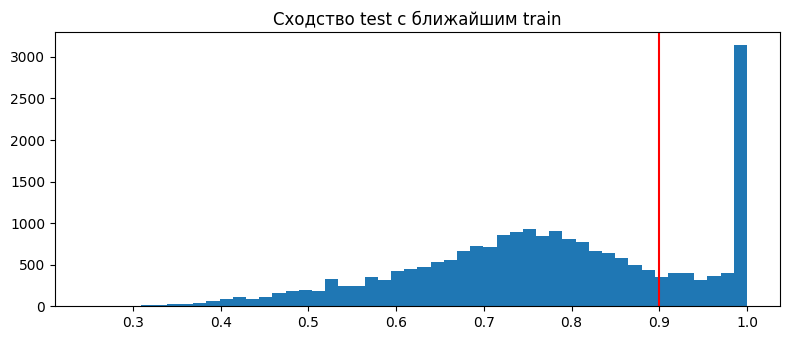

,title,nn_title,label,nn_label,nn_sim
202414,Қазақстан Республикасы Ауыл шаруашылығы министрлігі Агроөнеркәсіптік кешендегі мемлекеттік инспекция комитетінің кей...,Қазақстан Республикасы Ауыл шаруашылығы министрлігі Агроөнеркәсіптік кешендегі мемлекеттік инспекция комитетінің кей...,Бұйрық,Қаулы,0.998527
196721,Қазақстан Республикасы Ұлттық экономика министрінің кейбір бұйрықтарға өзгерістер енгізу туралы,Қазақстан Республикасы Ұлттық экономика министрінің кейбір бұйрықтарына өзгерістер енгізу туралы,Бұйрық,Бұйрық,0.944550
214422,"""Әуежайдың (әуеайлақтың) аумағында әуежай қызметіне жатпайтын қызметтер көрсетуге қол жеткізу қағидаларын бекіту тур...","""Әуежайдың аумағында әуежай қызметіне жатпайтын қызметтер көрсетуге қол жеткізу қағидаларын бекіту туралы"" Қазақстан...",Бұйрық,Бұйрық,0.906592
212168,"""Тегін медициналық көмектің кепілдік берілген көлемі шеңберінде және (немесе) міндетті әлеуметтік медициналық сақтан...","""Тегін медициналық көмектің кепілдік берілген көлемі шеңберінде және (немесе) міндетті әлеуметтік медициналық сақтан...",Бұйрық,Бұйрық,0.965275
203547,Шардара ауданы бойынша тұрғын үй сертификаттарының мөлшерін және алушылар санаттарының тізбесін айқындау туралы,Шет ауданы бойынша тұрғын үй сертификаттарының мөлшерін және алушылар санаттарының тізбесін айқындау туралы,Шешім,Шешім,0.906720


In [ ]:
plt.figure(figsize=(8, 3.5))
plt.hist(test["nn_sim"], bins=50)
plt.axvline(NEAR_DUP_THRESHOLD, color="red")
plt.title("Сходство test с ближайшим train")
plt.tight_layout()
plt.show()
test[(test["nn_sim"] >= NEAR_DUP_THRESHOLD) & (test["nn_sim"] < 0.999)].sample(5, random_state=SEED)[["title", "nn_title", "label", "nn_label", "nn_sim"]]

### 4.3 Решение по утечке

Разбиение уже временное, поэтому один и тот же акт не попадает в разные части. Дополнительно применяется групповая очистка по нормализованному названию
1. из val и test удаляются названия, которые точно встречаются в train
2. внутри train удаляются дубликаты (название, метка)
3. отдельно считается строгий test без почти-дубликатов (сходство с train не ниже порога), метрики даются для обоих вариантов

In [ ]:
val = val[~val["title_norm"].isin(train_titles)]
test = test[~test["title_norm"].isin(train_titles) & ~test["title_norm"].isin(set(val["title_norm"]))]
train = train.drop_duplicates(["title_norm", "label"])
test["is_strict"] = (test["nn_sim"] < NEAR_DUP_THRESHOLD).astype(int)

label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for c, i in label2id.items()}
for p in (train, val, test):
    p["y"] = p["label"].map(label2id)

train = train.reset_index(drop=True); val = val.reset_index(drop=True); test = test.reset_index(drop=True)
strict_mask = test["is_strict"].values == 1
print("train", len(train), "val", len(val), "test", len(test), "strict test", strict_mask.sum())

dist_tbl = pd.DataFrame({
    "train": train["label"].value_counts(normalize=True),
    "val": val["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).fillna(0).round(4).sort_values("train", ascending=False)
dist_tbl

train 130871 val 18231 test 16869 strict test 14368


,train,val,test
label,,,
Қаулы,0.4249,0.1714,0.2040
Шешім,0.3460,0.6790,0.5994
Бұйрық,0.1498,0.1251,0.1675
Өкім,0.0308,0.0066,0.0071
Жарлық,0.0240,0.0085,0.0074
Заң,0.0217,0.0061,0.0110
Нормативтік қаулы,0.0029,0.0032,0.0036


## 5. SQLite и общие функции

In [ ]:
con = sqlite3.connect(DB_PATH)
con.executescript('''
CREATE TABLE IF NOT EXISTS experiments(
    run_id TEXT PRIMARY KEY, model TEXT, target TEXT, train_size INTEGER, n_classes INTEGER,
    params INTEGER, size_mb REAL, train_time_s REAL, latency_cpu_s_1000 REAL, latency_gpu_s_1000 REAL,
    val_f1_macro REAL, test_f1_macro REAL, test_f1_weighted REAL, test_accuracy REAL,
    strict_test_f1_macro REAL, config TEXT, created_at TEXT);
CREATE TABLE IF NOT EXISTS predictions(
    run_id TEXT, row_id INTEGER, law_id TEXT, date_adopted TEXT, title TEXT,
    y_true TEXT, y_pred TEXT, confidence REAL, is_strict INTEGER);
CREATE TABLE IF NOT EXISTS per_class(
    run_id TEXT, label TEXT, precision REAL, recall REAL, f1 REAL, support INTEGER);
''')
con.commit()

def metrics(y_true, y_pred):
    return {
        "f1_macro": f1_score(y_true, y_pred, average="macro", labels=np.unique(y_true), zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
    }

def dir_size_mb(path):
    if os.path.isfile(path):
        return os.path.getsize(path) / 2**20
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 2**20

def log_run(model_name, val_probs, test_probs, params, size_mb, train_time, lat_cpu, lat_gpu, train_size, config):
    run_id = f"{model_name}_{TARGET}"
    vp = val_probs.argmax(1); tp = test_probs.argmax(1)
    mv = metrics(val["y"].values, vp)
    mt = metrics(test["y"].values, tp)
    ms = metrics(test["y"].values[strict_mask], tp[strict_mask])
    con.execute("DELETE FROM predictions WHERE run_id=?", (run_id,))
    con.execute("DELETE FROM per_class WHERE run_id=?", (run_id,))
    con.execute("INSERT OR REPLACE INTO experiments VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)", (
        run_id, model_name, TARGET, int(train_size), len(CLASSES), int(params), float(size_mb), float(train_time),
        float(lat_cpu), None if lat_gpu is None else float(lat_gpu),
        mv["f1_macro"], mt["f1_macro"], mt["f1_weighted"], mt["accuracy"], ms["f1_macro"],
        json.dumps(config, ensure_ascii=False), datetime.now().isoformat(timespec="seconds")))
    pred_rows = pd.DataFrame({
        "run_id": run_id, "row_id": test.index.values, "law_id": test["law_id"].values,
        "date_adopted": test["date"].dt.strftime("%Y-%m-%d").values, "title": test["title"].values,
        "y_true": test["label"].values, "y_pred": [id2label[i] for i in tp],
        "confidence": test_probs.max(1), "is_strict": test["is_strict"].values})
    pred_rows.to_sql("predictions", con, if_exists="append", index=False)
    rep = classification_report(test["y"].values, tp, labels=list(range(len(CLASSES))), target_names=CLASSES, output_dict=True, zero_division=0)
    pc = pd.DataFrame([{"run_id": run_id, "label": c, "precision": rep[c]["precision"], "recall": rep[c]["recall"],
                        "f1": rep[c]["f1-score"], "support": int(rep[c]["support"])} for c in CLASSES])
    pc.to_sql("per_class", con, if_exists="append", index=False)
    con.commit()
    shutil.copy(DB_PATH, DB_BACKUP)
    print(model_name)
    print("val F1-macro", round(mv["f1_macro"], 4))
    print("test F1-macro", round(mt["f1_macro"], 4), "accuracy", round(mt["accuracy"], 4))
    print("strict test F1-macro", round(ms["f1_macro"], 4))
    return run_id

latency_texts = test["title_norm"].sample(1000, random_state=SEED, replace=len(test) < 1000).tolist()

def measure_latency(predict_fn, texts=latency_texts, repeats=3):
    predict_fn(texts[:64])
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        predict_fn(texts)
        times.append(time.perf_counter() - t0)
    return float(np.median(times))

## 6. Baseline. TF-IDF + LogisticRegression

In [ ]:
def make_features():
    return FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=150000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=300000, sublinear_tf=True)),
    ])

def make_lr(C=4.0):
    return OneVsRestClassifier(LogisticRegression(C=C, solver="liblinear", class_weight="balanced", max_iter=2000))

_X = {}
def get_X():
    if not _X:
        t0 = time.perf_counter()
        feats = make_features()
        _X["tr"] = feats.fit_transform(train["title_norm"])
        _X["fit_time"] = time.perf_counter() - t0
        _X["va"] = feats.transform(val["title_norm"])
        _X["feats"] = feats
        print("матрица признаков", _X["tr"].shape)
    return _X

### 6.1 Кривая обучения (обоснование размера подвыборки для e5)

матрица признаков (130871, 242165)
2000 0.7374
5000 0.7669
10000 0.8041
20000 0.8162
40000 0.8319
80000 0.8403
130871 0.8992
 train_size  val_f1_macro
       2000      0.737421
       5000      0.766879
      10000      0.804127
      20000      0.816249
      40000      0.831884
      80000      0.840320
     130871      0.899197


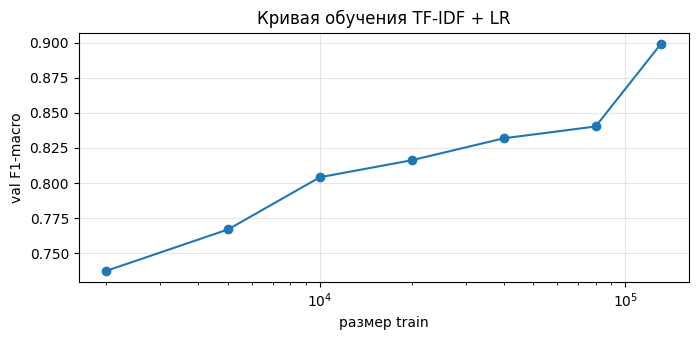

In [ ]:
if has("learning_curve.csv"):
    lc = pd.read_csv(f"{OUT}/learning_curve.csv")
    print("загружено из сохранения")
else:
    X = get_X()
    rng = np.random.default_rng(SEED)
    order = rng.permutation(len(train))
    sizes = [s for s in [2000, 5000, 10000, 20000, 40000, 80000] if s < len(train)] + [len(train)]
    lc = []
    for s in sizes:
        idx = order[:s]
        m = make_lr().fit(X["tr"][idx], train["y"].values[idx])
        f = f1_score(val["y"], m.predict(X["va"]), average="macro")
        lc.append((s, f))
        print(s, round(f, 4))
    lc = pd.DataFrame(lc, columns=["train_size", "val_f1_macro"])
    lc.to_csv(f"{OUT}/learning_curve.csv", index=False)
print(lc.to_string(index=False))
plt.figure(figsize=(7, 3.5))
plt.plot(lc["train_size"], lc["val_f1_macro"], marker="o")
plt.xscale("log")
plt.xlabel("размер train")
plt.ylabel("val F1-macro")
plt.title("Кривая обучения TF-IDF + LR")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

### 6.2 Подбор C и финальная модель

In [ ]:
if has("tfidf_best_c.json"):
    best_C = load_json("tfidf_best_c.json")["C"]
    print("загружено из сохранения")
else:
    X = get_X()
    best_C, best_f = None, -1
    for C in [1.0, 4.0, 16.0]:
        m = make_lr(C).fit(X["tr"], train["y"].values)
        f = f1_score(val["y"], m.predict(X["va"]), average="macro")
        print("C", C, "val F1-macro", round(f, 4))
        if f > best_f:
            best_C, best_f = C, f
    save_json({"C": best_C}, "tfidf_best_c.json")
print("best C", best_C)

C 1.0 val F1-macro 0.8905
C 4.0 val F1-macro 0.8992
C 16.0 val F1-macro 0.9016
best C 16.0


In [ ]:
tfidf_path = f"{OUT}/tfidf_lr.joblib"
if has("tfidf_lr.joblib") and has("tfidf_meta.json"):
    tfidf_lr = joblib.load(tfidf_path)
    tfidf_train_time = load_json("tfidf_meta.json")["train_time"]
    print("загружено из сохранения")
else:
    X = get_X()
    t0 = time.perf_counter()
    clf = make_lr(best_C).fit(X["tr"], train["y"].values)
    tfidf_train_time = X["fit_time"] + time.perf_counter() - t0
    tfidf_lr = Pipeline([("tfidf", X["feats"]), ("lr", clf)])
    joblib.dump(tfidf_lr, tfidf_path)
    save_json({"train_time": tfidf_train_time}, "tfidf_meta.json")
_X.clear()

def tfidf_predict_proba(texts):
    return tfidf_lr.predict_proba([norm_text(t) for t in texts])

tfidf_val_probs = tfidf_predict_proba(val["title_norm"].tolist())
tfidf_test_probs = tfidf_predict_proba(test["title_norm"].tolist())

tfidf_params = sum(e.coef_.size + e.intercept_.size for e in tfidf_lr.named_steps["lr"].estimators_)
n_feats = sum(len(t.vocabulary_) for _, t in tfidf_lr.named_steps["tfidf"].transformer_list)
tfidf_lat = measure_latency(tfidf_predict_proba)

tfidf_run = log_run("tfidf_lr", tfidf_val_probs, tfidf_test_probs, tfidf_params, dir_size_mb(tfidf_path),
                    tfidf_train_time, tfidf_lat, None, len(train), {"C": best_C, "n_features": n_feats})
print("признаков", n_feats, "параметров LR", tfidf_params)
print("размер МБ", round(dir_size_mb(tfidf_path), 1), "латентность на 1000 текстов, с", round(tfidf_lat, 3))

tfidf_lr
val F1-macro 0.9016
test F1-macro 0.9046 accuracy 0.9576
strict test F1-macro 0.8882
признаков 242165 параметров LR 1695162
размер МБ 24.5 латентность на 1000 текстов, с 0.463


## 7. Общий цикл обучения для трансформеров

In [ ]:
def class_weights(y, n):
    cnt = np.bincount(y, minlength=n).astype(float)
    w = 1.0 / np.sqrt(np.maximum(cnt, 1))
    return torch.tensor(w / w.mean(), dtype=torch.float)

def make_loader(ids, mask, y=None, batch_size=128, shuffle=False, generator=None):
    tensors = [torch.as_tensor(ids), torch.as_tensor(mask)]
    if y is not None:
        tensors.append(torch.as_tensor(y, dtype=torch.long))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle, generator=generator)

@torch.no_grad()
def predict_probs(model, ids, mask, batch_size=256, device=DEVICE):
    model.eval().to(device)
    out = []
    for b_ids, b_mask in make_loader(ids, mask, batch_size=batch_size):
        L = int(b_mask.sum(1).max())
        b_ids, b_mask = b_ids[:, :L], b_mask[:, :L]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(b_ids.to(device), b_mask.to(device))
        out.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(out)

def train_model(model, tr_ids, tr_mask, tr_y, va_ids, va_mask, va_y, epochs, lr, batch_size,
                weight_decay=0.01, patience=2, ckpt_path=None, save_every_min=10):
    model.to(DEVICE)
    n_batches = math.ceil(len(tr_y) / batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total = epochs * n_batches
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * total), total)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights(tr_y, len(CLASSES)).to(DEVICE), label_smoothing=0.05)
    use_amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    st = {"epoch": 1, "step": 0, "run_loss": 0.0, "best_f": -1.0, "best_state": None, "bad": 0, "history": [], "elapsed": 0.0}

    if ckpt_path and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        if use_amp and ck.get("scaler"):
            scaler.load_state_dict(ck["scaler"])
        st = ck["state"]
        print("продолжение с эпохи", st["epoch"], "шаг", st["step"], "из", n_batches)

    def save_ckpt():
        if not ckpt_path:
            return
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict() if use_amp else None, "state": st}, ckpt_path + ".tmp")
        os.replace(ckpt_path + ".tmp", ckpt_path)

    t0 = time.perf_counter() - st["elapsed"]
    while st["epoch"] <= epochs and st["bad"] < patience:
        ep = st["epoch"]
        model.train()
        loader = make_loader(tr_ids, tr_mask, tr_y, batch_size=batch_size, shuffle=True,
                             generator=torch.Generator().manual_seed(SEED + ep))
        last_save = time.perf_counter()
        for step, (b_ids, b_mask, b_y) in enumerate(loader):
            if step < st["step"]:
                continue
            L = int(b_mask.sum(1).max())
            b_ids, b_mask, b_y = b_ids[:, :L].to(DEVICE), b_mask[:, :L].to(DEVICE), b_y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = loss_fn(model(b_ids, b_mask), b_y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            st["run_loss"] += loss.item()
            st["step"] = step + 1
            if time.perf_counter() - last_save > save_every_min * 60:
                st["elapsed"] = time.perf_counter() - t0
                save_ckpt()
                last_save = time.perf_counter()
                print(f"epoch {ep} шаг {st['step']}/{n_batches} сохранён")
        vf = f1_score(va_y, predict_probs(model, va_ids, va_mask).argmax(1), average="macro")
        tl = st["run_loss"] / n_batches
        st["history"].append((ep, tl, vf))
        print(f"epoch {ep} loss {tl:.4f} val F1-macro {vf:.4f} time {time.perf_counter()-t0:.0f}s")
        if vf > st["best_f"]:
            st["best_f"], st["bad"] = vf, 0
            st["best_state"] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            st["bad"] += 1
        st["epoch"], st["step"], st["run_loss"] = ep + 1, 0, 0.0
        st["elapsed"] = time.perf_counter() - t0
        save_ckpt()

    model.load_state_dict(st["best_state"])
    return model, st["elapsed"], pd.DataFrame(st["history"], columns=["epoch", "train_loss", "val_f1_macro"])

def n_params(model):
    return sum(p.numel() for p in model.parameters())

## 8. Компактный трансформер с нуля

### 8.1 BPE-токенизатор (обучается только на train)

In [ ]:
bpe_path = f"{OUT}/tiny_bpe.json"
if has("tiny_bpe.json") and has("tiny_meta.json"):
    bpe = Tokenizer.from_file(bpe_path)
    TINY_MAX_LEN = load_json("tiny_meta.json")["max_len"]
    print("загружено из сохранения")
else:
    bpe = Tokenizer(models.BPE(unk_token="[UNK]"))
    bpe.normalizer = normalizers.Sequence([normalizers.NFKC(), normalizers.Lowercase()])
    bpe.pre_tokenizer = pre_tokenizers.Sequence([pre_tokenizers.Punctuation(), pre_tokenizers.Metaspace()])
    bpe.decoder = decoders.Metaspace()
    bpe_trainer = trainers.BpeTrainer(vocab_size=8000, min_frequency=2, special_tokens=["[PAD]", "[UNK]", "[CLS]"])
    bpe.train_from_iterator(train["title_norm"].tolist(), trainer=bpe_trainer)
    bpe.post_processor = processors.TemplateProcessing(single="[CLS] $A", special_tokens=[("[CLS]", bpe.token_to_id("[CLS]"))])
    bpe_lens = np.array([len(e.ids) for e in bpe.encode_batch(train["title_norm"].sample(min(20000, len(train)), random_state=SEED).tolist())])
    TINY_MAX_LEN = int(min(128, np.percentile(bpe_lens, 99) + 2))
    print("длина в BPE токенах median", np.median(bpe_lens), "p95", np.percentile(bpe_lens, 95), "p99", np.percentile(bpe_lens, 99))
    bpe.enable_truncation(TINY_MAX_LEN)
    bpe.enable_padding(pad_id=0, pad_token="[PAD]", length=TINY_MAX_LEN)
    bpe.save(bpe_path)
    save_json({"max_len": TINY_MAX_LEN}, "tiny_meta.json")
bpe.enable_truncation(TINY_MAX_LEN)
bpe.enable_padding(pad_id=0, pad_token="[PAD]", length=TINY_MAX_LEN)
print("размер словаря", bpe.get_vocab_size(), "max_len", TINY_MAX_LEN)
print(bpe.encode(train["title_norm"].iloc[0]).tokens)

def bpe_encode(texts):
    enc = bpe.encode_batch([norm_text(t) for t in texts])
    ids = np.array([e.ids for e in enc], dtype=np.int64)
    return ids, (ids != 0)

tr_ids, tr_mask = bpe_encode(train["title_norm"].tolist())
va_ids, va_mask = bpe_encode(val["title_norm"].tolist())
te_ids, te_mask = bpe_encode(test["title_norm"].tolist())
print("доля UNK в val", round((va_ids == 1).sum() / va_mask.sum(), 5))

длина в BPE токенах median 23.0 p95 51.0 p99 76.0
размер словаря 8000 max_len 78
['[CLS]', '▁қылм', 'ыс', 'пен', '▁келтірілген', '▁материалдық', '▁зал', 'алды', '▁өтеу', '▁жөнінде', '▁заңдарды', '▁соттардың', '▁қолдану', '▁тәжірибесі', '▁туралы', '▁с', 'с', 'ро', '▁жоғарғы', '▁соты', '▁пленумының', '▁197', '9', '▁-', '▁жылғы', '▁23', '▁-', '▁наурыздағы', '▁n', '▁1', '▁қаулысын', '▁', '▁(', '▁пленумының', '▁198', '4', '▁-', '▁жылғы', '▁25', '▁-', '▁сәуірдегі', '▁n', '▁7', '▁қаулысымен', '▁енгізілген', '▁толықтырулар', 'ымен', '▁қоса', '▁)', '▁республика', '▁соттарының', '▁орындау', '▁барысы', '▁туралы', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
доля UNK в val 0.0


### 8.2 Модель

In [ ]:
class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, n_classes, max_len, d_model=256, n_heads=4, n_layers=4, d_ff=768, dropout=0.1):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, ids, mask):
        mask = mask.bool()
        pos = torch.arange(ids.size(1), device=ids.device).unsqueeze(0)
        x = self.drop(self.tok(ids) + self.pos(pos))
        x = self.norm(self.enc(x, src_key_padding_mask=~mask))
        m = mask.unsqueeze(-1).to(x.dtype)
        x = (x * m).sum(1) / m.sum(1).clamp(min=1)
        return self.head(self.drop(x))

TINY_CFG = dict(d_model=256, n_heads=4, n_layers=4, d_ff=768, dropout=0.1)
set_seed()
tiny = TinyTransformer(bpe.get_vocab_size(), len(CLASSES), TINY_MAX_LEN, **TINY_CFG)
print("параметров", n_params(tiny))
assert n_params(tiny) <= 10_000_000

параметров 4704007


### 8.3 Обучение

In [ ]:
tiny_path = f"{OUT}/tiny_transformer.pt"
tiny_ckpt = f"{OUT}/tiny_checkpoint.pt"
if has("tiny_transformer.pt") and has("tiny_train.json"):
    tiny.load_state_dict(torch.load(tiny_path, map_location="cpu"))
    tiny.to(DEVICE)
    meta = load_json("tiny_train.json")
    tiny_train_time, tiny_hist = meta["train_time"], pd.DataFrame(meta["history"])
    print("загружено из сохранения")
else:
    tiny, tiny_train_time, tiny_hist = train_model(tiny, tr_ids, tr_mask, train["y"].values, va_ids, va_mask, val["y"].values,
                                                   epochs=10, lr=5e-4, batch_size=256, patience=3, ckpt_path=tiny_ckpt, save_every_min=5)
    torch.save(tiny.state_dict(), tiny_path)
    save_json({"train_time": tiny_train_time, "history": tiny_hist.to_dict("list")}, "tiny_train.json")
    if os.path.exists(tiny_ckpt):
        os.remove(tiny_ckpt)
print("время обучения, с", round(tiny_train_time))
print(tiny_hist.to_string(index=False))

epoch 1 loss 1.2492 val F1-macro 0.7546 time 35s
epoch 2 loss 0.9141 val F1-macro 0.7692 time 70s
epoch 3 loss 0.8506 val F1-macro 0.8180 time 106s
epoch 4 loss 0.8095 val F1-macro 0.7996 time 143s
epoch 5 loss 0.7811 val F1-macro 0.8249 time 180s
epoch 6 loss 0.7552 val F1-macro 0.8356 time 217s
epoch 7 loss 0.7337 val F1-macro 0.8471 time 254s
epoch 8 loss 0.7158 val F1-macro 0.8281 time 290s
epoch 9 loss 0.7021 val F1-macro 0.8396 time 327s
epoch 10 loss 0.6912 val F1-macro 0.8398 time 364s
время обучения, с 364
 epoch  train_loss  val_f1_macro
     1    1.249193      0.754597
     2    0.914060      0.769248
     3    0.850574      0.818041
     4    0.809511      0.799618
     5    0.781058      0.824931
     6    0.755246      0.835630
     7    0.733700      0.847122
     8    0.715784      0.828087
     9    0.702080      0.839616
    10    0.691230      0.839836


In [ ]:
tiny_size = dir_size_mb(tiny_path) + dir_size_mb(bpe_path)

tiny_val_probs = predict_probs(tiny, va_ids, va_mask)
tiny_test_probs = predict_probs(tiny, te_ids, te_mask)

tiny_cpu = copy.deepcopy(tiny).to("cpu")
def tiny_predict_proba(texts, model=tiny_cpu, device="cpu"):
    ids, mask = bpe_encode(texts)
    return predict_probs(model, ids, mask, device=device)

tiny_lat_cpu = measure_latency(tiny_predict_proba)
tiny_lat_gpu = measure_latency(lambda t: tiny_predict_proba(t, tiny, "cuda")) if DEVICE == "cuda" else None

tiny_run = log_run("tiny_transformer", tiny_val_probs, tiny_test_probs, n_params(tiny), tiny_size, tiny_train_time,
                   tiny_lat_cpu, tiny_lat_gpu, len(train), {**TINY_CFG, "vocab": bpe.get_vocab_size(), "max_len": TINY_MAX_LEN})
print("размер МБ", round(tiny_size, 1), "CPU латентность, с", round(tiny_lat_cpu, 3), "GPU латентность, с", tiny_lat_gpu)

tiny_transformer
val F1-macro 0.8471
test F1-macro 0.8523 accuracy 0.951
strict test F1-macro 0.827
размер МБ 18.6 CPU латентность, с 7.881 GPU латентность, с 0.2364697860002707


## 9. Дообучение multilingual-e5-small

Модель содержит около 118 млн параметров, поэтому она обучается на стратифицированной подвыборке train. Размер подвыборки выбран по кривой обучения из раздела 6.1, где после нескольких десятков тысяч примеров прирост F1-macro становится небольшим. На GPU берётся 60 тыс. примеров, на CPU 12 тыс.

In [ ]:
e5_sub = train if E5_TRAIN_SIZE >= len(train) else train_test_split(train, train_size=E5_TRAIN_SIZE, stratify=train["y"], random_state=SEED)[0]
e5_tok = AutoTokenizer.from_pretrained(E5_NAME)
E5_MAX_LEN = int(min(128, np.percentile(d_e5, 99) + 4))
print("train для e5", len(e5_sub), "max_len", E5_MAX_LEN)

def e5_encode(texts):
    enc = e5_tok(["query: " + norm_text(t) for t in texts], max_length=E5_MAX_LEN, truncation=True, padding="max_length", return_tensors="np")
    return enc["input_ids"].astype(np.int64), enc["attention_mask"].astype(bool)

e5_tr_ids, e5_tr_mask = e5_encode(e5_sub["title_norm"].tolist())
e5_va_ids, e5_va_mask = e5_encode(val["title_norm"].tolist())
e5_te_ids, e5_te_mask = e5_encode(test["title_norm"].tolist())

train для e5 60000 max_len 110


In [ ]:
class E5Classifier(nn.Module):
    def __init__(self, name, n_classes, dropout=0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(name)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(self.encoder.config.hidden_size, n_classes)

    def forward(self, ids, mask):
        h = self.encoder(input_ids=ids, attention_mask=mask.long()).last_hidden_state
        m = mask.unsqueeze(-1).to(h.dtype)
        x = (h * m).sum(1) / m.sum(1).clamp(min=1)
        return self.head(self.drop(x))

set_seed()
e5 = E5Classifier(E5_NAME, len(CLASSES))
print("параметров", n_params(e5))
e5_dir = f"{OUT}/e5_small_cls"
e5_ckpt = f"{OUT}/e5_checkpoint.pt"
os.makedirs(e5_dir, exist_ok=True)
if os.path.exists(f"{e5_dir}/model.pt") and has("e5_train.json"):
    e5.load_state_dict(torch.load(f"{e5_dir}/model.pt", map_location="cpu"))
    e5.to(DEVICE)
    meta = load_json("e5_train.json")
    e5_train_time, e5_hist = meta["train_time"], pd.DataFrame(meta["history"])
    print("загружено из сохранения")
else:
    e5, e5_train_time, e5_hist = train_model(e5, e5_tr_ids, e5_tr_mask, e5_sub["y"].values, e5_va_ids, e5_va_mask, val["y"].values,
                                             epochs=3, lr=5e-5, batch_size=64, patience=1, ckpt_path=e5_ckpt, save_every_min=15)
    torch.save(e5.state_dict(), f"{e5_dir}/model.pt")
    e5_tok.save_pretrained(e5_dir)
    save_json({"train_time": e5_train_time, "history": e5_hist.to_dict("list")}, "e5_train.json")
    if os.path.exists(e5_ckpt):
        os.remove(e5_ckpt)
print("время обучения, с", round(e5_train_time))
print(e5_hist.to_string(index=False))

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

параметров 117656455
epoch 1 loss 1.1090 val F1-macro 0.8716 time 157s
epoch 2 loss 0.8369 val F1-macro 0.9151 time 329s
epoch 3 loss 0.7786 val F1-macro 0.9083 time 572s
время обучения, с 572
 epoch  train_loss  val_f1_macro
     1    1.108975      0.871605
     2    0.836919      0.915060
     3    0.778589      0.908277


In [ ]:
e5_size = dir_size_mb(e5_dir)

e5_val_probs = predict_probs(e5, e5_va_ids, e5_va_mask, batch_size=128)
e5_test_probs = predict_probs(e5, e5_te_ids, e5_te_mask, batch_size=128)

def e5_predict_proba(texts, model=None, device="cpu"):
    ids, mask = e5_encode(texts)
    return predict_probs(model, ids, mask, batch_size=64, device=device)

e5_lat_gpu = measure_latency(lambda t: e5_predict_proba(t, e5, "cuda")) if DEVICE == "cuda" else None
e5_cpu = copy.deepcopy(e5).to("cpu")
e5_lat_cpu = measure_latency(lambda t: e5_predict_proba(t, e5_cpu, "cpu"), repeats=1)
if DEVICE == "cuda":
    e5.to("cuda")

e5_run = log_run("e5_small_ft", e5_val_probs, e5_test_probs, n_params(e5), e5_size, e5_train_time,
                 e5_lat_cpu, e5_lat_gpu, len(e5_sub), {"base": E5_NAME, "max_len": E5_MAX_LEN, "epochs": 3, "lr": 5e-5})
print("размер МБ", round(e5_size, 1), "CPU латентность, с", round(e5_lat_cpu, 3), "GPU латентность, с", e5_lat_gpu)

e5_small_ft
val F1-macro 0.9151
test F1-macro 0.8941 accuracy 0.9564
strict test F1-macro 0.8792
размер МБ 465.2 CPU латентность, с 90.764 GPU латентность, с 1.0259384819992192


## 10. Сравнение моделей

In [ ]:
cmp = pd.read_sql('''
SELECT model, train_size, params, ROUND(size_mb, 1) AS size_mb, ROUND(train_time_s, 0) AS train_time_s,
       ROUND(latency_cpu_s_1000, 3) AS cpu_s_per_1000, ROUND(latency_gpu_s_1000, 3) AS gpu_s_per_1000,
       ROUND(val_f1_macro, 4) AS val_f1_macro, ROUND(test_f1_macro, 4) AS test_f1_macro,
       ROUND(strict_test_f1_macro, 4) AS strict_test_f1_macro, ROUND(test_accuracy, 4) AS test_accuracy
FROM experiments WHERE target = ? ORDER BY test_f1_macro DESC
''', con, params=(TARGET,))
cmp

,model,train_size,params,size_mb,train_time_s,cpu_s_per_1000,gpu_s_per_1000,val_f1_macro,test_f1_macro,strict_test_f1_macro,test_accuracy
0,tfidf_lr,130871,1695162,24.5,467.0,0.463,NaN,0.9016,0.9046,0.8882,0.9576
1,e5_small_ft,60000,117656455,465.2,572.0,90.764,1.026,0.9151,0.8941,0.8792,0.9564
2,tiny_transformer,130871,4704007,18.6,364.0,7.881,0.236,0.8471,0.8523,0.8270,0.9510


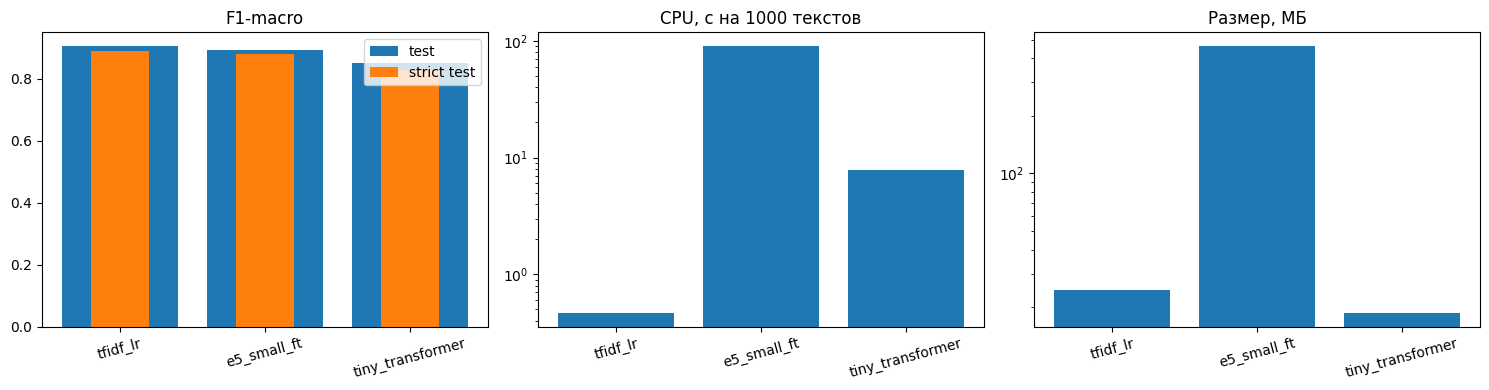

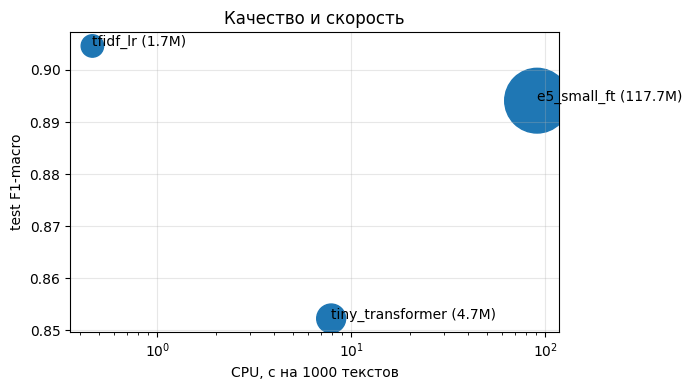

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(cmp["model"], cmp["test_f1_macro"], label="test")
ax[0].bar(cmp["model"], cmp["strict_test_f1_macro"], width=0.4, label="strict test")
ax[0].set_title("F1-macro")
ax[0].legend()
ax[1].bar(cmp["model"], cmp["cpu_s_per_1000"])
ax[1].set_yscale("log")
ax[1].set_title("CPU, с на 1000 текстов")
ax[2].bar(cmp["model"], cmp["size_mb"])
ax[2].set_yscale("log")
ax[2].set_title("Размер, МБ")
for a in ax:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(cmp["cpu_s_per_1000"], cmp["test_f1_macro"], s=np.sqrt(cmp["params"]) / 5)
for _, r in cmp.iterrows():
    plt.annotate(f"{r['model']} ({r['params']/1e6:.1f}M)", (r["cpu_s_per_1000"], r["test_f1_macro"]))
plt.xscale("log")
plt.xlabel("CPU, с на 1000 текстов")
plt.ylabel("test F1-macro")
plt.title("Качество и скорость")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()

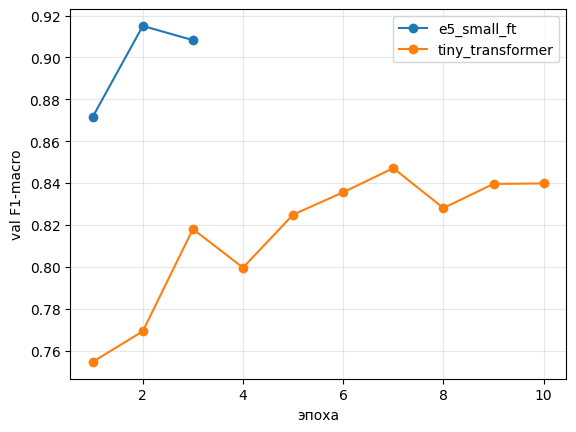

In [ ]:
hist = pd.concat([tiny_hist.assign(model="tiny_transformer"), e5_hist.assign(model="e5_small_ft")])
for m, h in hist.groupby("model"):
    plt.plot(h["epoch"], h["val_f1_macro"], marker="o", label=m)
plt.xlabel("эпоха")
plt.ylabel("val F1-macro")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 11. Error analysis

In [ ]:
best_run = pd.read_sql("SELECT run_id FROM experiments WHERE target=? ORDER BY val_f1_macro DESC LIMIT 1", con, params=(TARGET,))["run_id"][0]
print("лучшая модель по val", best_run)
pc = pd.read_sql("SELECT run_id, label, ROUND(f1, 3) AS f1, support FROM per_class WHERE run_id LIKE ?", con, params=(f"%_{TARGET}",))
pc.pivot(index="label", columns="run_id", values="f1").join(pc.drop_duplicates("label").set_index("label")["support"]).sort_values("support", ascending=False)

лучшая модель по val e5_small_ft_act_form


,e5_small_ft_act_form,tfidf_lr_act_form,tiny_transformer_act_form,support
label,,,,
Шешім,0.980,0.981,0.981,10112
Қаулы,0.905,0.908,0.894,3441
Бұйрық,0.949,0.947,0.936,2826
Заң,0.976,0.967,0.970,185
Жарлық,0.784,0.814,0.746,125
Өкім,0.785,0.884,0.800,120
Нормативтік қаулы,0.879,0.830,0.639,60


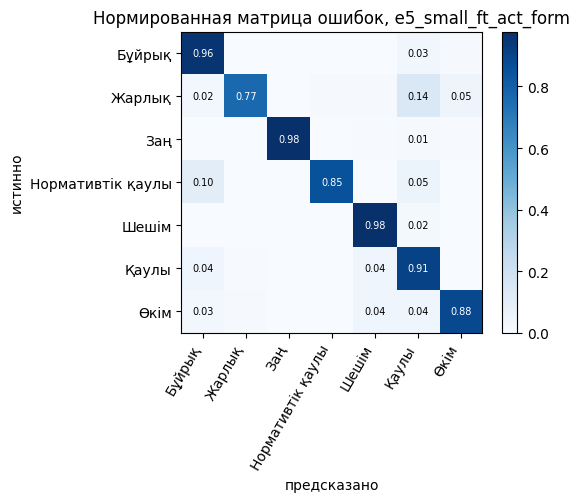

In [ ]:
bp = pd.read_sql("SELECT * FROM predictions WHERE run_id=?", con, params=(best_run,))
cm = confusion_matrix(bp["y_true"], bp["y_pred"], labels=CLASSES, normalize="true")
plt.figure(figsize=(max(6, len(CLASSES) * 0.6), max(5, len(CLASSES) * 0.5)))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(CLASSES)), CLASSES, rotation=60, ha="right")
plt.yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] >= 0.01:
            plt.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
plt.xlabel("предсказано")
plt.ylabel("истинно")
plt.title(f"Нормированная матрица ошибок, {best_run}")
plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
pd.read_sql('''
SELECT y_true, y_pred, COUNT(*) AS n, ROUND(AVG(confidence), 3) AS avg_conf
FROM predictions WHERE run_id=? AND y_true <> y_pred
GROUP BY y_true, y_pred ORDER BY n DESC LIMIT 15
''', con, params=(best_run,))

,y_true,y_pred,n,avg_conf
0,Шешім,Қаулы,210,0.770
1,Қаулы,Шешім,148,0.616
2,Қаулы,Бұйрық,136,0.664
3,Бұйрық,Қаулы,91,0.598
4,Бұйрық,Өкім,22,0.596
5,Қаулы,Жарлық,21,0.768
6,Жарлық,Қаулы,18,0.618
7,Шешім,Бұйрық,17,0.811
8,Қаулы,Өкім,11,0.519
9,Бұйрық,Шешім,8,0.583


In [ ]:
pd.read_sql('''
SELECT title, y_true, y_pred, ROUND(confidence, 3) AS confidence, date_adopted
FROM predictions WHERE run_id=? AND y_true <> y_pred
ORDER BY confidence DESC LIMIT 15
''', con, params=(best_run,))

,title,y_true,y_pred,confidence,date_adopted
0,"""Алдын ала болу қорытындылары бойынша жыл сайынғы жинақталған баяндаманы дайындау қағидаларын бекіту туралы"" Адам құ...",Бұйрық,Өкім,0.891,2026-02-16
1,Ревизиялық (тексеру) комиссиялардың төрағасы мен мүшелерінің лауазымдарына кандидаттарды іріктеу қағидалары және ола...,Қаулы,Бұйрық,0.890,2024-09-09
2,Қазақстан Республикасы Жоғары Сот Кенесінің жанындағы Сот төрелігі академиясында оқулық басылымдар мен оқу-әдiстемел...,Шешім,Бұйрық,0.890,2024-12-18
3,Ведомстволық статистикалық байқауларды жүргізу үшін статистикалық нысандарды және оларды толтыру нұсқаулықтарын бекі...,Қаулы,Бұйрық,0.890,2025-06-23
4,"""Әскери қызмет және әскери қызметшілердің мәртебесі туралы"" 2012 жылғы 16 ақпандағы Қазақстан Республикасы Заңының 2...",Нормативтік қаулы,Бұйрық,0.888,2025-01-24
5,"2023 жылғы 20 сәуірдегі Қазақстан Республикасы Әлеуметтік кодексінің 196-бабы 1-тармағының, 202-бабы 2-тармағының, 2...",Нормативтік қаулы,Бұйрық,0.888,2026-05-18
6,"""Қазақстан Республикасы Жоғары Сот Кеңесінің жанындағы Сот төрелігі академиясына оқуға қабылдау қағидаларын бекіту т...",Шешім,Өкім,0.886,2025-05-30
7,"2014 жылғы 5 шілдедегі Қазақстан Республикасы Қылмыстық-атқару кодексінің 109-бабы екінші бөлігінің, 134-бабы бірінш...",Нормативтік қаулы,Бұйрық,0.885,2024-12-27
8,"""Қазақстан Республикасы Жоғары Сот Кеңесінің жанындағы Сот төрелігі академиясына оқуға қабылдау қағидаларын бекіту т...",Шешім,Өкім,0.885,2025-08-11
9,Қазақстан Республикасының көші-қон саясатының 2030 жылға дейінгі тұжырымдамасын бекіту туралы,Қаулы,Жарлық,0.883,2025-12-15


In [ ]:
bp["len_words"] = bp["title"].map(lambda t: len(norm_text(t).split()))
bp["len_bin"] = pd.cut(bp["len_words"], [0, 5, 10, 15, 20, 30, 1000], labels=["1-5", "6-10", "11-15", "16-20", "21-30", "30+"])
bp["error"] = (bp["y_true"] != bp["y_pred"]).astype(int)
bp["year"] = bp["date_adopted"].str[:4]
print(bp.groupby("len_bin", observed=True)["error"].agg(["mean", "size"]).round(3).to_string())
print(bp.groupby("year")["error"].agg(["mean", "size"]).round(3).to_string())
print(bp.groupby("is_strict")["error"].agg(["mean", "size"]).round(3).to_string())

          mean  size
len_bin             
1-5      0.321    56
6-10     0.066  2637
11-15    0.084  2357
16-20    0.054  2229
21-30    0.024  6668
30+      0.022  2922
       mean   size
year              
2024  0.032   4008
2025  0.044  11632
2026  0.079   1229
            mean   size
is_strict              
0          0.024   2501
1          0.047  14368


In [ ]:
bins = pd.cut(bp["confidence"], [0, .5, .7, .9, .99, 1.0])
print(bp.groupby(bins, observed=True)["error"].agg(["mean", "size"]).round(3).to_string())

              mean   size
confidence               
(0.0, 0.5]   0.546    240
(0.5, 0.7]   0.404    534
(0.7, 0.9]   0.024  15924
(0.9, 0.99]  0.000    171


In [ ]:
agree = pd.read_sql(f'''
SELECT a.row_id, a.title, a.y_true,
       a.y_pred AS tfidf_lr, b.y_pred AS tiny_transformer, c.y_pred AS e5_small_ft
FROM predictions a
JOIN predictions b ON a.row_id = b.row_id AND b.run_id = 'tiny_transformer_{TARGET}'
JOIN predictions c ON a.row_id = c.row_id AND c.run_id = 'e5_small_ft_{TARGET}'
WHERE a.run_id = 'tfidf_lr_{TARGET}'
''', con)
ok = agree[["tfidf_lr", "tiny_transformer", "e5_small_ft"]].eq(agree["y_true"], axis=0)
print("все три верно", round(ok.all(axis=1).mean(), 4))
print("все три ошиблись", round((~ok).all(axis=1).mean(), 4))
for m in ok.columns:
    print("верно только", m, int((ok[m] & ~ok.drop(columns=m).any(axis=1)).sum()))
print("oracle accuracy", round(ok.any(axis=1).mean(), 4))
agree[(~ok).all(axis=1)].sample(min(10, int((~ok).all(axis=1).sum())), random_state=SEED)

все три верно 0.9295
все три ошиблись 0.0236
верно только tfidf_lr 127
верно только tiny_transformer 65
верно только e5_small_ft 100
oracle accuracy 0.9764


,row_id,title,y_true,tfidf_lr,tiny_transformer,e5_small_ft
8563,8563,"""Нурлэнд"" жауапкершілігі шектеулі серіктестігіне қауымдық сервитут белгілеу туралы",Шешім,Қаулы,Қаулы,Қаулы
16840,16840,Қазақстан Республикасында цифрлық активтер индустриясын ынталандыру және дамыту жөніндегі шаралар туралы,Жарлық,Өкім,Өкім,Қаулы
1897,1897,Қазақстан Республикасы Жоғары Сот Кеңесінің жанындағы Сот төрелігі академиясында қашықтықтан оқыту бойынша оқу проце...,Шешім,Бұйрық,Бұйрық,Бұйрық
9467,9467,"""B2Gold Kazakhstan Ltd"" жеке компаниясына қауымдық сервитутты белгілеу туралы",Шешім,Қаулы,Қаулы,Қаулы
4369,4369,Солтүстік Қазақстан облысы Шал ақын ауданының жергілікті бюджеттен қаржыландырылатын ұйымдар жұмыскерлерінің лауазым...,Шешім,Қаулы,Қаулы,Қаулы
4165,4165,"Азаматтық қорғаныс бойынша қалаларды топтарға, ұйымдарды санаттарға жатқызу жөніндегі тізбелерді бекіту туралы",Шешім,Бұйрық,Бұйрық,Бұйрық
16081,16081,"Қазақстан Республикасының Үкіметі белгілеген шекті шама шеңберінде ""Әлеуметтік медициналық сақтандыру қоры"" коммерци...",Бұйрық,Қаулы,Қаулы,Қаулы
4469,4469,Қаумдық сервитутты орнату туралы,Шешім,Қаулы,Өкім,Қаулы
9924,9924,"""Қазақстан Алюминийі"" акционерлік қоғамына жария сервитут белгілеу туралы",Шешім,Қаулы,Қаулы,Қаулы
5585,5585,Жергілікті бюджеттен қаржыландырылатын ұйымдар жұмыскерлерінің айлық лауазымдық айлықақыларына ынталандыру үстемеақы...,Шешім,Бұйрық,Қаулы,Қаулы


## 12. Предсказание для введённого текста

In [ ]:
def predict_text(text):
    rows = []
    for name, fn in [("tfidf_lr", tfidf_predict_proba),
                     ("tiny_transformer", tiny_predict_proba),
                     ("e5_small_ft", lambda t: e5_predict_proba(t, e5, DEVICE))]:
        p = fn([text])[0]
        top3 = np.argsort(-p)[:3]
        rows.append({"model": name, "prediction": id2label[top3[0]], "confidence": round(float(p[top3[0]]), 3),
                     "top3": ", ".join(f"{id2label[i]} {p[i]:.2f}" for i in top3)})
    return pd.DataFrame(rows)

for t in test.sample(3, random_state=1)["title"]:
    print(t)
    print("истинная метка", test.loc[test["title"] == t, "label"].iloc[0])
    print(predict_text(t).to_string(index=False))
    print()

Қобда аудандық мәслихатының 2023 жылғы 29 желтоқсандағы № 143 "2024-2026 жылдарға арналған И. Құрманов атындағы ауылдық округінің бюджетін бекіту туралы" шешіміне өзгерістер енгізу туралы
истинная метка Шешім
           model prediction  confidence                                            top3
        tfidf_lr      Шешім       1.000            Шешім 1.00, Жарлық 0.00, Бұйрық 0.00
tiny_transformer      Шешім       0.859    Шешім 0.86, Нормативтік қаулы 0.06, Заң 0.02
     e5_small_ft      Шешім       0.846 Шешім 0.85, Нормативтік қаулы 0.07, Жарлық 0.02

"Атырау облысының аумағында бұқаралық ақпарат құралдарында мемлекеттік ақпараттық саясатты жүргізу үшін сатып алынатын көрсетілетін қызметтердің құнын айқындау әдістемесін бекіту туралы" Атырау облысы әкімдігінің 2022 жылғы 24 наурыздағы № 58 қаулысының күші жойылды деп тану туралы
истинная метка Қаулы
           model prediction  confidence                                            top3
        tfidf_lr      Қаулы       0.997       

In [ ]:
con.close()
shutil.copy(DB_PATH, DB_BACKUP)
print(sorted(os.listdir(OUT)))

['e5_small_cls', 'e5_train.json', 'experiments.db', 'learning_curve.csv', 'near_dup.parquet', 'tfidf_best_c.json', 'tfidf_lr.joblib', 'tfidf_meta.json', 'tiny_bpe.json', 'tiny_meta.json', 'tiny_train.json', 'tiny_transformer.pt']


## 13. Интерактивный ввод

Эта ячейка последняя, потому что ждёт ввод и блокирует Run all. Всё важное к этому моменту уже сохранено.

In [ ]:
while True:
    text = input("Введите название акта (пустая строка для выхода): ").strip()
    if not text:
        break
    print(predict_text(text).to_string(index=False))
    print()

Введите название акта (пустая строка для выхода): 
